In [1]:
import os
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import ImageDataGenerator

print("TensorFlow:", tf.__version__)

TensorFlow: 2.20.0


In [2]:

print(os.listdir("/kaggle/input/datasets"))

['misrakahmed']


In [3]:
print(os.listdir("/kaggle/input/datasets/misrakahmed"))

['vegetable-image-dataset']


In [4]:
base = "/kaggle/input/datasets/misrakahmed/vegetable-image-dataset"

for root, dirs, files in os.walk(base):
    if "train" in dirs or "validation" in dirs or "test" in dirs:
        print(root)
        print(dirs)
        break

/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images
['validation', 'test', 'train']


In [5]:
dataset_path = root

train_path = dataset_path + "/train"
val_path = dataset_path + "/validation"
test_path = dataset_path + "/test"

print(train_path)
print(val_path)
print(test_path)

/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/train
/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/validation
/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test


In [6]:
train_path = "/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/train"
val_path = "/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/validation"
test_path = "/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test"

In [7]:

classes = os.listdir(train_path)

print("Number of classes:", len(classes))
print("Classes:", classes)

Number of classes: 15
Classes: ['Broccoli', 'Capsicum', 'Bottle_Gourd', 'Radish', 'Tomato', 'Brinjal', 'Pumpkin', 'Carrot', 'Papaya', 'Cabbage', 'Bitter_Gourd', 'Cauliflower', 'Bean', 'Cucumber', 'Potato']


In [8]:
print("Train:", sum(len(files) for _, _, files in os.walk(train_path)))
print("Validation:", sum(len(files) for _, _, files in os.walk(val_path)))
print("Test:", sum(len(files) for _, _, files in os.walk(test_path)))

Train: 15000
Validation: 3000
Test: 3000


In [9]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_gen = ImageDataGenerator(
    rescale=1./255,
    horizontal_flip=True
)

normal_gen = ImageDataGenerator(
    rescale=1./255
)

In [10]:
train = train_gen.flow_from_directory(
    train_path,
    target_size=(128, 128),
    batch_size=32,
    class_mode="categorical"
)

validation = normal_gen.flow_from_directory(
    val_path,
    target_size=(128, 128),
    batch_size=32,
    class_mode="categorical"
)

test = normal_gen.flow_from_directory(
    test_path,
    target_size=(128, 128),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)

Found 15000 images belonging to 15 classes.
Found 3000 images belonging to 15 classes.
Found 3000 images belonging to 15 classes.


In [11]:
class_names = list(train.class_indices.keys())

print(class_names)

['Bean', 'Bitter_Gourd', 'Bottle_Gourd', 'Brinjal', 'Broccoli', 'Cabbage', 'Capsicum', 'Carrot', 'Cauliflower', 'Cucumber', 'Papaya', 'Potato', 'Pumpkin', 'Radish', 'Tomato']


In [12]:
import tensorflow as tf

model = tf.keras.Sequential([
    
    tf.keras.layers.Input(shape=(128, 128, 3)),
    
    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    
    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    
    tf.keras.layers.Flatten(),
    
    tf.keras.layers.Dense(64, activation="relu"),
    
    tf.keras.layers.Dense(15, activation="softmax")
])

2026-10-27 18:11:41.226730: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [13]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     3,686,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │           975 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,706,831 (14.14 MB)

 Trainable params: 3,706,831 (14.14 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "best_model.keras",
    monitor="val_loss",
    save_best_only=True
)

In [16]:
history = model.fit(
    train,
    validation_data=validation,
    epochs=2,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/2
469/469 ━━━━━━━━━━━━━━━━━━━━ 173s 367ms/step - accuracy: 0.5868 - loss: 1.2452 - val_accuracy: 0.7747 - val_loss: 0.7109
Epoch 2/2
469/469 ━━━━━━━━━━━━━━━━━━━━ 125s 267ms/step - accuracy: 0.8492 - loss: 0.4763 - val_accuracy: 0.8430 - val_loss: 0.4963


In [17]:
test_loss, test_accuracy = model.evaluate(test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

94/94 ━━━━━━━━━━━━━━━━━━━━ 39s 419ms/step - accuracy: 0.8423 - loss: 0.4763
Test Loss: 0.47631365060806274
Test Accuracy: 0.8423333168029785


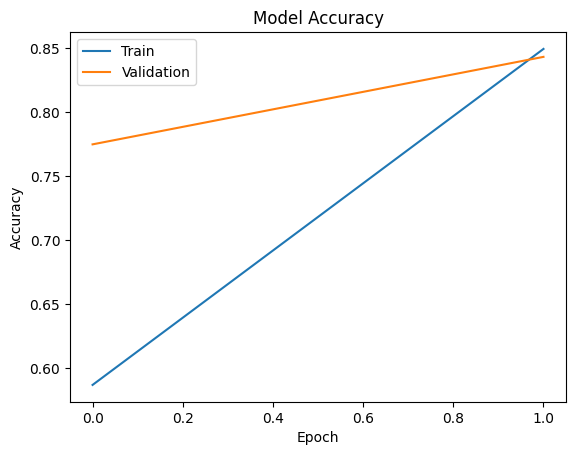

In [18]:
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

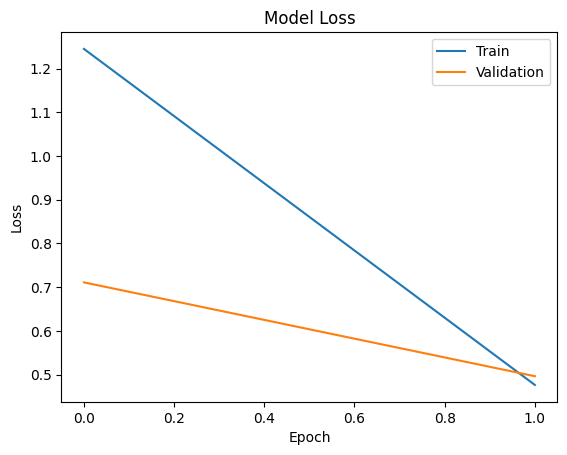

In [19]:
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")

plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step


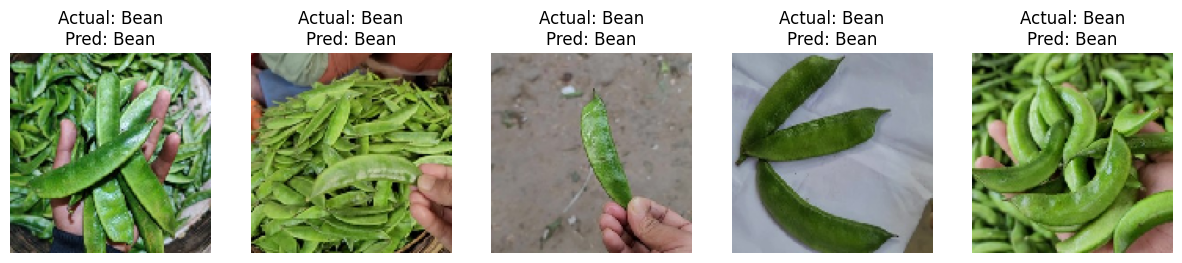

In [20]:
import numpy as np

images, labels = next(test)

predictions = model.predict(images)

plt.figure(figsize=(15, 5))

for i in range(5):

    actual = np.argmax(labels[i])
    predicted = np.argmax(predictions[i])

    plt.subplot(1, 5, i + 1)
    plt.imshow(images[i])

    plt.title(
        "Actual: " + class_names[actual] +
        "\nPred: " + class_names[predicted]
    )

    plt.axis("off")

plt.show()

In [21]:
model.save("vegetable_cnn.keras")

print("Model Saved Successfully")

Model Saved Successfully


In [22]:
import json

with open("class_names.json", "w") as f:
    json.dump(class_names, f)

print("Class Names Saved")

Class Names Saved


In [23]:
loaded_model = tf.keras.models.load_model(
    "vegetable_cnn.keras"
)

print("Model Loaded Successfully")

Model Loaded Successfully
